# Visualising results

Notebook purpose:
- Load DiD analysis outputs from R into Python
- Plot main results figures
- Inspect relevant nuances

#### 1. Set-up

In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [58]:
from ipcei_spillovers.io import data_path, results_path, load_df, save_df, save_fig

from ipcei_spillovers.plotting import (
    COLORS,
    style_ax
)

In [59]:
# ============================================================
# Load data
# ============================================================

firm_master_ipcei = load_df(
    "interim", "combined", "firm_master_ipcei_corrected_extended_jan26.csv", low_memory=False
)
att_summary = load_df(
    "processed", "r_output", "att_summary_all.csv", low_memory=False
)

event_study = load_df(
    "processed", "r_output", "event_study_all.csv", low_memory=False
)

att_channels = load_df(
    "processed", "r_output", "att_channels_table.csv", low_memory=False
)
firm_month_outcomes = load_df(
    "interim", "combined", "firm_month_outcomes_extended_jan26.csv",
    low_memory=False
)

print(f"firm_month_outcomes: {firm_month_outcomes.shape}")
print(f"firm_master_ipcei: {firm_master_ipcei.shape}")
print(f"att_summary: {att_summary.shape}")
print(f"event_study: {event_study.shape}")
print(f"att_channels: {att_channels.shape}")

firm_month_outcomes: (986263, 8)
firm_master_ipcei: (239782, 101)
att_summary: (8, 5)
event_study: (128, 6)
att_channels: (10, 6)


#### 2. Main figures

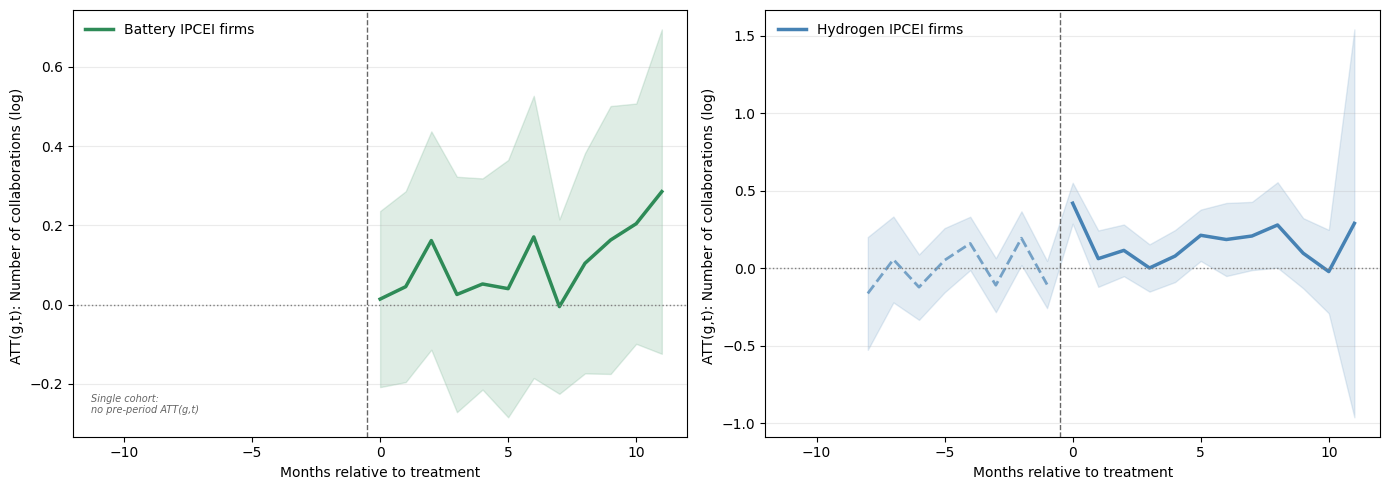

In [60]:
# ============================================================
# Figure 1: Main event study — total collaborations
# ============================================================

def plot_main_event_study(event_study):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    specs = [
        ("Battery — total collabs",  "Battery IPCEI firms",  COLORS["two"][1]),
        ("Hydrogen — total collabs", "Hydrogen IPCEI firms", COLORS["two"][0]),
    ]

    for ax, (label, title, color) in zip(axes, specs):
        df = event_study[event_study["label"] == label].copy()

        if df.empty:
            print(f"WARNING: no rows found for label '{label}'")
            ax.set_title(f"{title} — no data")
            continue

        df = df[(df["e"] >= -12) & (df["e"] <= 12)]
        pre  = df[df["e"] < 0]
        post = df[df["e"] >= 0]

        ax.fill_between(df["e"], df["cil"], df["ciu"],
                        color=color, alpha=0.15)

        if not pre.empty:
            ax.plot(pre["e"], pre["att"], color=color, linewidth=2,
                    linestyle="--", alpha=0.7)
        ax.plot(post["e"], post["att"], color=color, linewidth=2.5,
                label=title)

        ax.axhline(0,    linestyle=":",  color="grey",    linewidth=1)
        ax.axvline(-0.5, linestyle="--", color="#666666", linewidth=1)
        ax.set_xlim(-12, 12)

        # Note for Battery (no pre-period)
        if pre.empty:
            ax.text(0.03, 0.05,
                    "Single cohort:\nno pre-period ATT(g,t)",
                    transform=ax.transAxes,
                    fontsize=7, color="#666666", va="bottom", ha="left",
                    style="italic")

        ax.set_xlabel("Months relative to treatment")
        ax.set_ylabel("ATT(g,t): Number of collaborations (log) ")
        ax.set_title(title)
        ax.legend(frameon=False)
        style_ax(ax)

    plt.tight_layout()
    save_fig(fig, "results_main", "collaborations_total_event_study")
    plt.show()

plot_main_event_study(event_study)

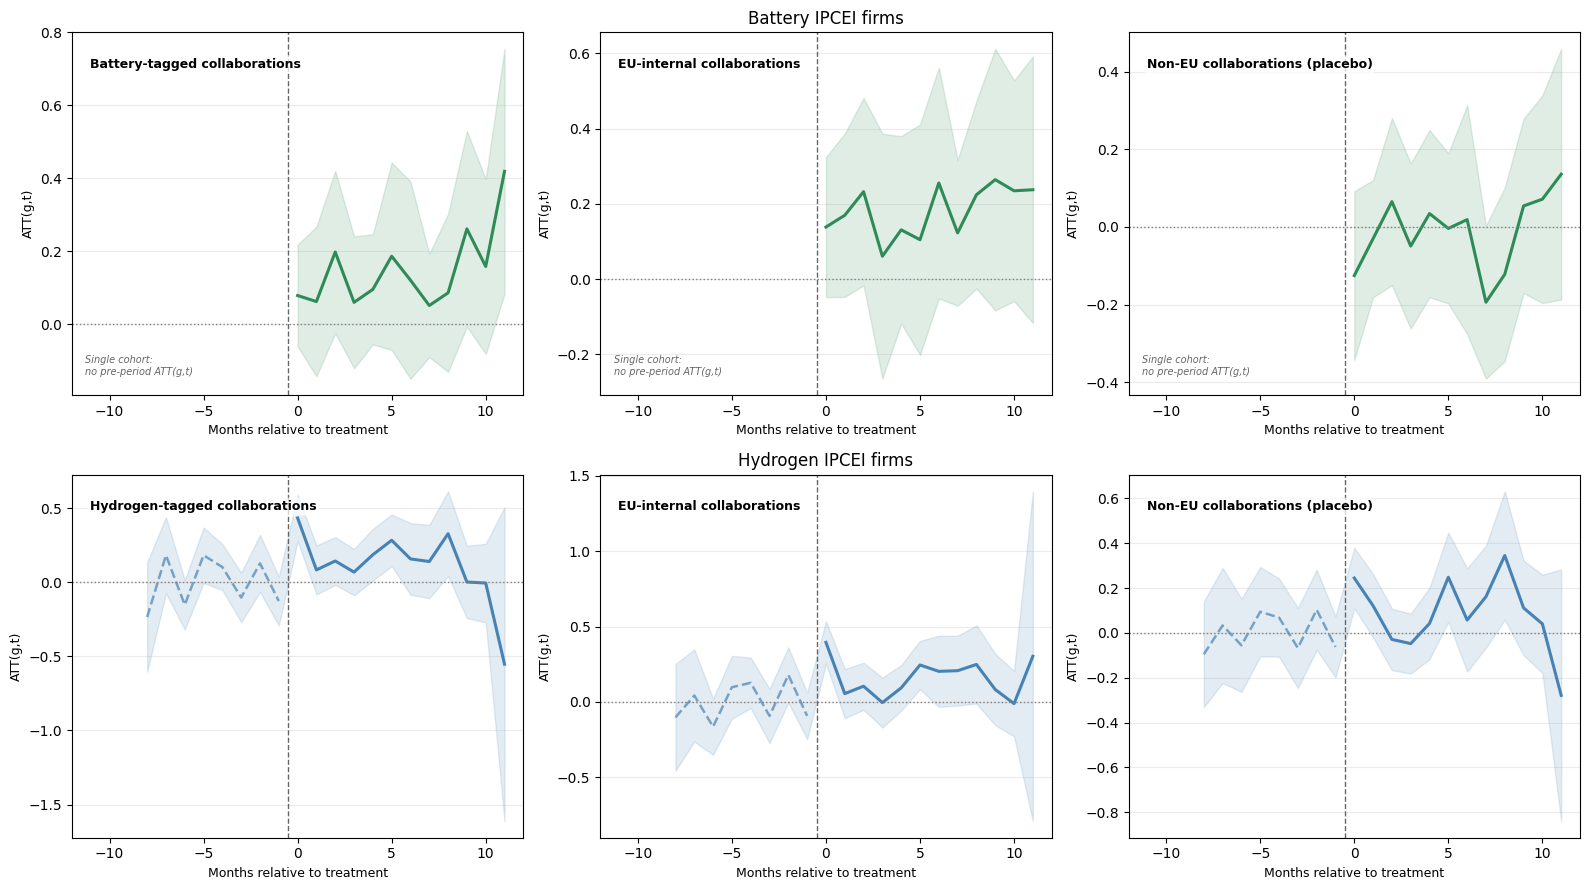

In [71]:
# ============================================================
# Figure 2: Channel decomposition event studies
# ============================================================

def plot_channel_event_studies(event_study):
    channel_specs = [
        ("Battery — tech collabs",   "Battery-tagged collaborations",  COLORS["two"][1]),
        ("Battery — EU-internal",    "EU-internal collaborations",   COLORS["two"][1]),
        ("Battery — non-EU",         "Non-EU collaborations (placebo)",      COLORS["two"][1]),
        ("Hydrogen — tech collabs",  "Hydrogen-tagged collaborations", COLORS["two"][0]),
        ("Hydrogen — EU-internal",   "EU-internal collaborations",   COLORS["two"][0]),
        ("Hydrogen — non-EU",        "Non-EU collaborations (placebo)",      COLORS["two"][0]),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=False)

    # Use a fixed x-range that covers both Battery (post-only) and Hydrogen (pre+post)
    x_min, x_max = -12, 12

    for ax, (label, panel_label, color) in zip(axes.flat, channel_specs):
        df = event_study[event_study["label"] == label].copy()
        df = df[(df["e"] >= x_min) & (df["e"] <= x_max)]

        pre  = df[df["e"] < 0]
        post = df[df["e"] >= 0]

        ax.fill_between(df["e"], df["cil"], df["ciu"],
                        color=color, alpha=0.15)

        if not pre.empty:
            ax.plot(pre["e"], pre["att"], color=color, linewidth=1.8,
                    linestyle="--", alpha=0.7)
        ax.plot(post["e"], post["att"], color=color, linewidth=2.2)

        ax.axhline(0,    linestyle=":",  color="grey",    linewidth=1)
        ax.axvline(-0.5, linestyle="--", color="#666666", linewidth=1)

        ax.set_xlim(x_min, x_max)
        ax.set_xlabel("Months relative to treatment", fontsize=9)
        ax.set_ylabel("ATT(g,t)", fontsize=9)

        # Within-panel label (top-left)
        ax.text(0.04, 0.93, panel_label,
                transform=ax.transAxes,
                fontsize=9, fontweight="bold", va="top", ha="left",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, ec="none"))

        # Note bottom-left for single-cohort panels
        if pre.empty:
            ax.text(0.03, 0.05,
                    "Single cohort:\nno pre-period ATT(g,t)",
                    transform=ax.transAxes,
                    fontsize=7, color="#666666", va="bottom", ha="left",
                    style="italic")

        style_ax(ax)
        if ax in axes[:, 1]:
            ax.set_title("Battery IPCEI firms" if "Battery" in label else "Hydrogen IPCEI firms")

    plt.tight_layout()
    save_fig(fig, "results_main", "collaborations_channels_event_study")
    plt.show()

plot_channel_event_studies(event_study)

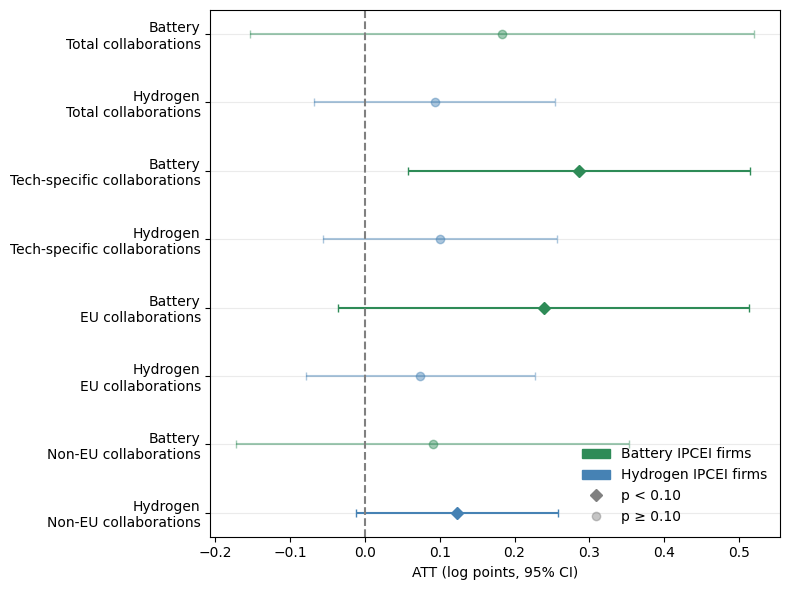

In [67]:
# ============================================================
# Figure 3: ATT coefficient plot
# ============================================================

def plot_att_coefficients(att_channels):

    df = att_channels.copy()

    # Normalize column names
    df.columns = [c.strip().title() for c in df.columns]

    # Remove robustness rows
    df = df[~df["Outcome"].str.contains("EU-internal", case=False)]

    # Rename outcomes
    df["Outcome"] = df["Outcome"].replace({
        "Total collabs": "Total collaborations",
        "Battery-tech collabs": "Tech-specific collaborations",
        "Hydrogen-tech collabs": "Tech-specific collaborations",
        "EU collabs (EU HQ only)": "EU collaborations",
        "Non-EU collabs": "Non-EU collaborations"
    })

    # Confidence intervals
    df["Ci_Lo"] = df["Att"] - 1.96 * df["Se"]
    df["Ci_Hi"] = df["Att"] + 1.96 * df["Se"]

    df["Sig"] = df["P_Value"] < 0.10

    # Order outcomes
    outcome_order = [
        "Non-EU collaborations",
        "EU collaborations",
        "Tech-specific collaborations",
        "Total collaborations"
    ]

    df["Outcome"] = pd.Categorical(
        df["Outcome"],
        categories=outcome_order,
        ordered=True
    )

    df = df.sort_values(["Outcome","Technology"], ascending=[True, False])

    # Labels
    df["Outcome"] = df["Outcome"].astype(str)
    df["Technology"] = df["Technology"].astype(str)

    df["Y_Label"] = df["Technology"] + "\n" + df["Outcome"]

    fig, ax = plt.subplots(figsize=(8,6))

    for _, row in df.iterrows():

        color = COLORS["two"][1] if row["Technology"] == "Battery" else COLORS["two"][0]
        alpha = 1.0 if row["Sig"] else 0.45
        marker = "D" if row["Sig"] else "o"

        ax.errorbar(
            row["Att"],
            row["Y_Label"],
            xerr=[[row["Att"]-row["Ci_Lo"]],[row["Ci_Hi"]-row["Att"]]],
            fmt=marker,
            color=color,
            alpha=alpha,
            capsize=3,
            linewidth=1.5,
            markersize=6
        )

    ax.axvline(0, linestyle="--", color="grey")

    ax.set_xlabel("ATT (log points, 95% CI)")

    patches = [
        mpatches.Patch(color=COLORS["two"][1], label="Battery IPCEI firms"),
        mpatches.Patch(color=COLORS["two"][0], label="Hydrogen IPCEI firms"),
        plt.Line2D([0],[0],marker="D",color="grey",linestyle="None",markersize=6,label="p < 0.10"),
        plt.Line2D([0],[0],marker="o",color="grey",linestyle="None",markersize=6,alpha=0.45,label="p ≥ 0.10")
    ]

    ax.legend(handles=patches, frameon=False, loc="lower right")

    style_ax(ax)

    plt.tight_layout()

    save_fig(fig,"results_main","att_coefficients")

    plt.show()


# RUN
plot_att_coefficients(att_channels)

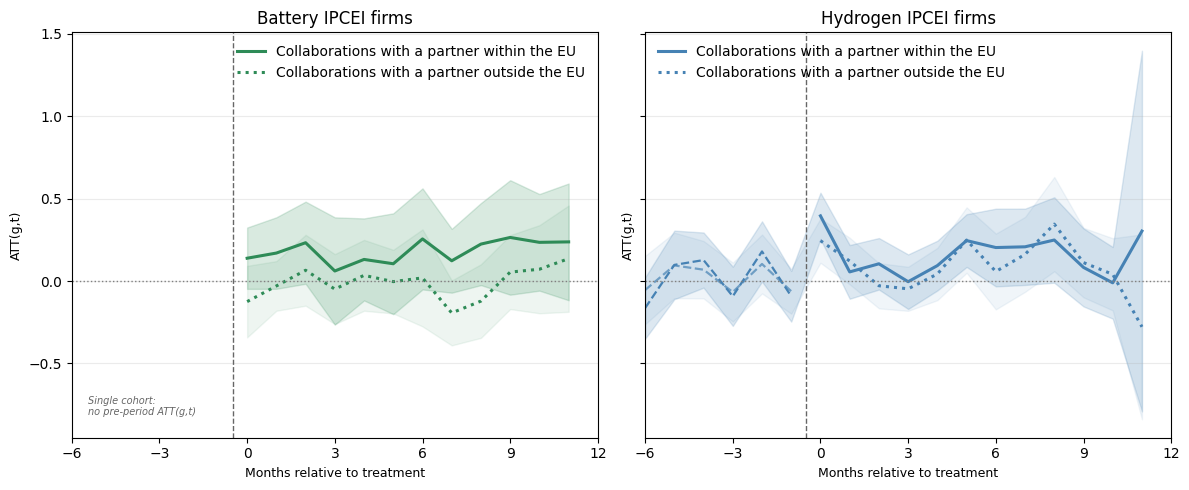

In [69]:
# ============================================================
# EU collaboration event studies
# ============================================================

def plot_eu_event_overlay(event_study):

    fig, axes = plt.subplots(1,2,figsize=(12,5),sharey=True)

    specs = [
        ("Battery", "Battery — EU-internal", "Battery — non-EU"),
        ("Hydrogen", "Hydrogen — EU-internal", "Hydrogen — non-EU"),
    ]

    for ax,(tech,eu_label,non_label) in zip(axes,specs):

        eu = event_study[event_study["label"] == eu_label].copy()
        non = event_study[event_study["label"] == non_label].copy()

        eu = eu[(eu["e"] >= -6) & (eu["e"] <= 12)]
        non = non[(non["e"] >= -6) & (non["e"] <= 12)]

        base_color = COLORS["two"][1] if tech=="Battery" else COLORS["two"][0]

        # --- EU collaborations ---
        ax.fill_between(eu["e"], eu["cil"], eu["ciu"],
                        color=base_color, alpha=0.18)

        pre = eu[eu["e"] < 0]
        post = eu[eu["e"] >= 0]

        if not pre.empty:
            ax.plot(pre["e"], pre["att"],
                    color=base_color,
                    linestyle="--", linewidth=1.6)

        ax.plot(post["e"], post["att"],
                color=base_color,
                linewidth=2.2,
                label="Collaborations with a partner within the EU")

        # --- NON EU collaborations ---
        ax.fill_between(non["e"], non["cil"], non["ciu"],
                        color=base_color, alpha=0.08)

        pre = non[non["e"] < 0]
        post = non[non["e"] >= 0]

        if not pre.empty:
            ax.plot(pre["e"], pre["att"],
                    color=base_color,
                    linestyle="--", linewidth=1.6, alpha=0.7)

        ax.plot(post["e"], post["att"],
                color=base_color,
                linewidth=2.2,
                linestyle=":",
                label="Collaborations with a partner outside the EU")

        ax.axhline(0, linestyle=":", color="grey", linewidth=1)
        ax.axvline(-0.5, linestyle="--", color="#666666", linewidth=1)

        ax.set_xlim(-6,12)
        ax.set_xticks(range(-6,13,3))

        ax.set_xlabel("Months relative to treatment", fontsize=9)
        ax.set_ylabel("ATT(g,t)", fontsize=9)

        ax.legend(frameon=False)

        # Detect if either series has a pre-period
        has_pre = (
            (not total[total["e"] < 0].empty if "total" in locals() else False) or
            (not techs[techs["e"] < 0].empty if "techs" in locals() else False) or
            (not eu[eu["e"] < 0].empty if "eu" in locals() else False) or
            (not non[non["e"] < 0].empty if "non" in locals() else False)
        )

        if not has_pre:
            ax.text(
                0.03, 0.05,
                "Single cohort:\nno pre-period ATT(g,t)",
                transform=ax.transAxes,
                fontsize=7,
                color="#666666",
                va="bottom",
                ha="left",
                style="italic"
            )

        style_ax(ax)
        ax.set_title(f"{tech} IPCEI firms")

    plt.tight_layout()

    save_fig(fig,"results_main","eu_event_overlay")

    plt.show()


plot_eu_event_overlay(event_study)

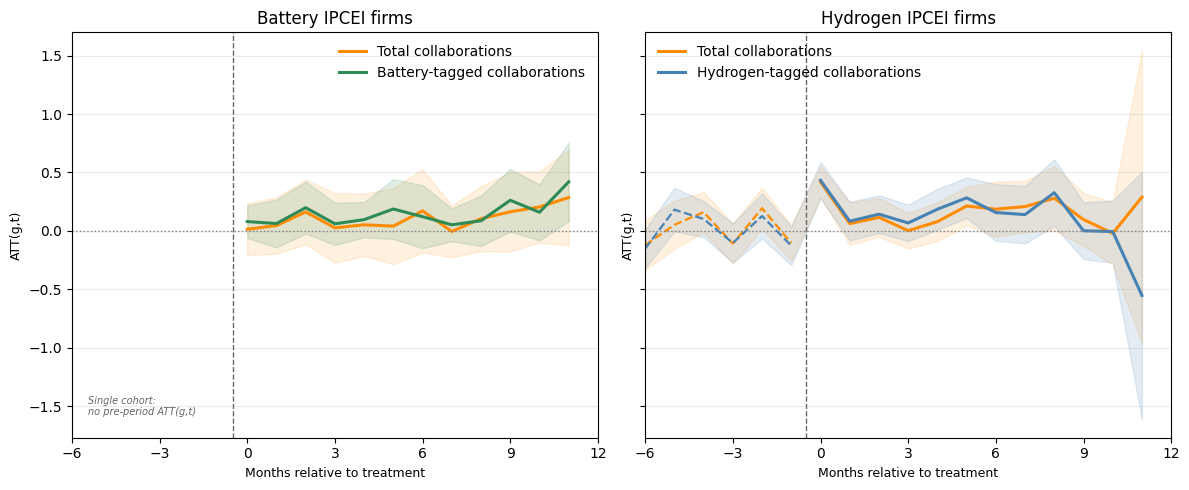

In [72]:
# ============================================================
# Technology channel event studies (clean version)
# ============================================================

def plot_tech_event_overlay(event_study):

    fig, axes = plt.subplots(1, 2, figsize=(12,5), sharey=True)

    specs = [
        ("Battery", "Battery — total collabs", "Battery — tech collabs"),
        ("Hydrogen", "Hydrogen — total collabs", "Hydrogen — tech collabs"),
    ]

    for ax,(tech,total_label,tech_label) in zip(axes,specs):

        total = event_study[event_study["label"] == total_label].copy()
        techs = event_study[event_study["label"] == tech_label].copy()

        total = total[(total["e"] >= -6) & (total["e"] <= 12)]
        techs = techs[(techs["e"] >= -6) & (techs["e"] <= 12)]

        # --- TOTAL collaborations ---
        ax.fill_between(total["e"], total["cil"], total["ciu"],
                        color=COLORS["three"][2], alpha=0.12)

        pre = total[total["e"] < 0]
        post = total[total["e"] >= 0]

        if not pre.empty:
            ax.plot(pre["e"], pre["att"],
                    color=COLORS["three"][2],
                    linestyle="--", linewidth=1.6)

        ax.plot(post["e"], post["att"],
                color=COLORS["three"][2],
                linewidth=2.2,
                label="Total collaborations")

        # --- TECH collaborations ---
        color = COLORS["two"][1] if tech=="Battery" else COLORS["two"][0]

        ax.fill_between(techs["e"], techs["cil"], techs["ciu"],
                        color=color, alpha=0.15)

        pre = techs[techs["e"] < 0]
        post = techs[techs["e"] >= 0]

        if not pre.empty:
            ax.plot(pre["e"], pre["att"],
                    color=color,
                    linestyle="--", linewidth=1.6)

        label = (
            "Battery-tagged collaborations"
            if tech=="Battery"
            else "Hydrogen-tagged collaborations"
        )

        ax.plot(post["e"], post["att"],
                color=color,
                linewidth=2.2,
                label=label)

        ax.axhline(0, linestyle=":", color="grey", linewidth=1)
        ax.axvline(-0.5, linestyle="--", color="#666666", linewidth=1)

        ax.set_xlim(-6,12)
        ax.set_xticks(range(-6,13,3))

        ax.set_xlabel("Months relative to treatment", fontsize=9)
        ax.set_ylabel("ATT(g,t)", fontsize=9)

        ax.legend(frameon=False)

        # Detect if either series has a pre-period
        has_pre = (
            (not total[total["e"] < 0].empty if "total" in locals() else False) or
            (not techs[techs["e"] < 0].empty if "techs" in locals() else False) or
            (not eu[eu["e"] < 0].empty if "eu" in locals() else False) or
            (not non[non["e"] < 0].empty if "non" in locals() else False)
        )

        if not has_pre:
            ax.text(
                0.03, 0.05,
                "Single cohort:\nno pre-period ATT(g,t)",
                transform=ax.transAxes,
                fontsize=7,
                color="#666666",
                va="bottom",
                ha="left",
                style="italic"
            )

        style_ax(ax)
        ax.set_title(f"{tech} IPCEI firms")

    plt.tight_layout()

    save_fig(fig,"results_main","tech_event_overlay")

    plt.show()


plot_tech_event_overlay(event_study)

#### 3. Annotated trajectories

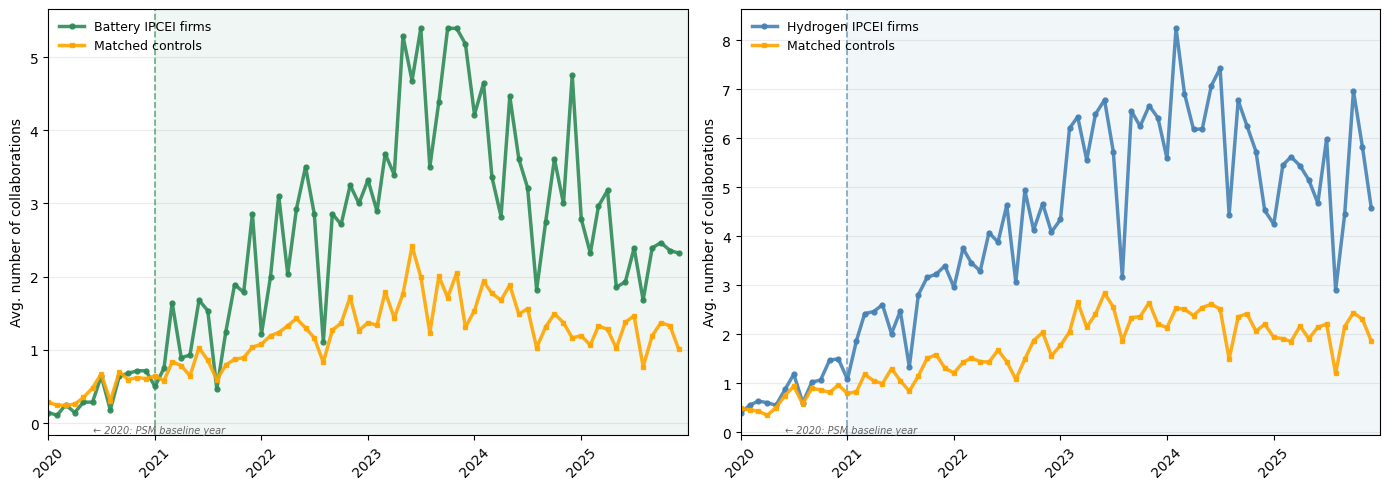

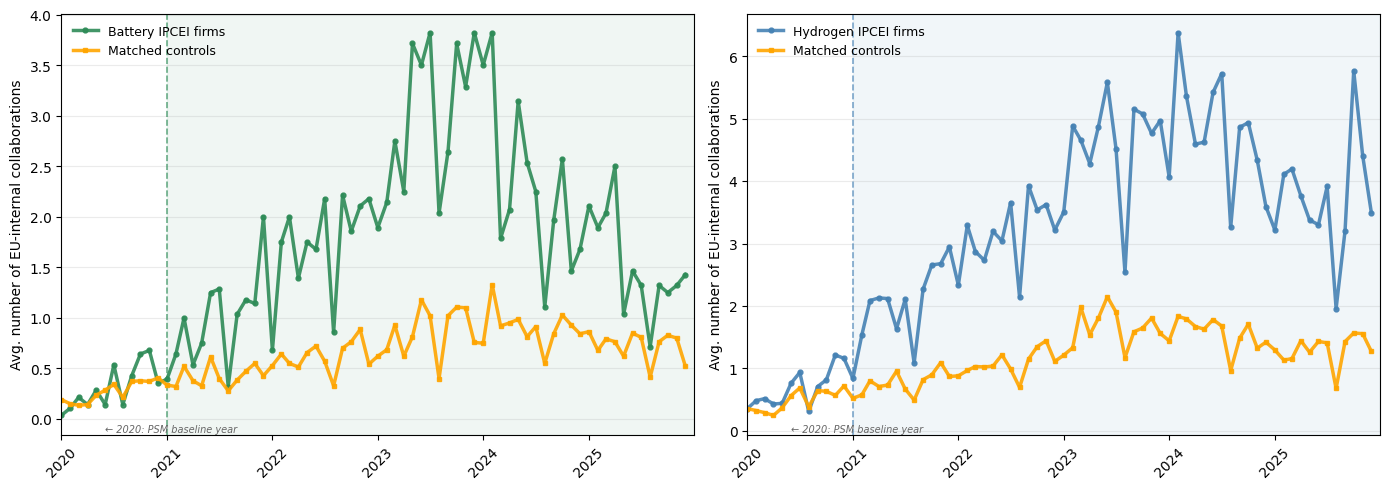

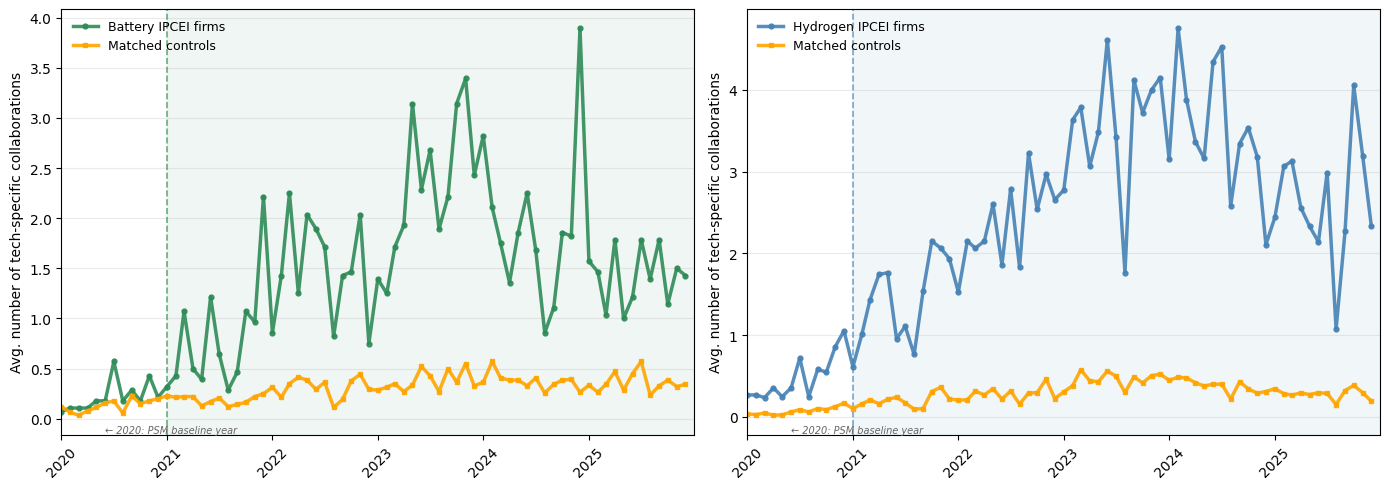

In [75]:
# ============================================================
# Annotated outcome trajectories — channels
# ============================================================

def plot_annotated_trajectories(battery_cs, hydrogen_cs,
                                outcome_col="n_collabs",
                                ylabel="Avg. number of collaborations",
                                figname="collaborations_annotated_trajectories"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    panels = [
        (battery_cs,  "Battery IPCEI",  COLORS["two"][1], "2021-01-01"),
        (hydrogen_cs, "Hydrogen IPCEI", COLORS["two"][0], "2021-01-01"),
    ]

    for ax, (panel, title, color, treat_start) in zip(axes, panels):
        p = panel.copy()
        p["month_dt"] = pd.to_datetime(p["month"])

        if outcome_col not in p.columns:
            print(f"WARNING: column '{outcome_col}' not found. Available: {p.columns.tolist()}")
            continue

        treated_traj = p[p["is_treated"] == 1].groupby("month_dt")[outcome_col].mean()
        control_traj = p[p["is_control"] == 1].groupby("month_dt")[outcome_col].mean()

        ax.axvspan(pd.Timestamp(treat_start), pd.Timestamp("2025-12-31"),
                   alpha=0.07, color=color)
        ax.axvline(pd.Timestamp(treat_start), linestyle="--",
                   color=color, linewidth=1.2, alpha=0.7)

        ax.plot(treated_traj.index, treated_traj.values,
                color=color, linewidth=2.5, marker="o",
                markersize=3.5, label=f"{title} firms", alpha=0.9)
        ax.plot(control_traj.index, control_traj.values,
                color="#FFA500", linewidth=2.5, marker="s",
                markersize=3.5, label="Matched controls", alpha=0.9)

        ax.set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2025-12-31"))
        #ax.set_xlabel("Month")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.legend(frameon=False, loc="upper left", fontsize=9)
        ax.tick_params(axis="x", rotation=45)

        # Baseline note on x-axis
        ax.text(pd.Timestamp("2020-06-01"), ax.get_ylim()[0],
                "← 2020: PSM baseline year",
                fontsize=7, color="#666666", va="bottom", style="italic")

        style_ax(ax)

    plt.tight_layout()
    save_fig(fig, "results", "results_main", figname)
    plt.show()

# Total collabs (already working)
plot_annotated_trajectories(battery_cs, hydrogen_cs)

# EU-internal collabs
plot_annotated_trajectories(
    battery_cs, hydrogen_cs,
    outcome_col="n_collabs_eu_primary",
    ylabel="Avg. number of EU-internal collaborations",
    figname="eu_collabs_annotated_trajectories"
)

# Tech-specific collabs
# Battery panel uses n_collabs_battery, Hydrogen uses n_collabs_hydrogen
# These differ per technology so we call separately and combine manually
def plot_tech_trajectories(battery_cs, hydrogen_cs):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    configs = [
        (battery_cs,  "n_collabs_battery",  "Battery IPCEI",  COLORS["two"][1], "2021-01-01"),
        (hydrogen_cs, "n_collabs_hydrogen", "Hydrogen IPCEI", COLORS["two"][0], "2021-01-01"),
    ]

    for ax, (panel, col, title, color, treat_start) in zip(axes, configs):
        p = panel.copy()
        p["month_dt"] = pd.to_datetime(p["month"])

        treated_traj = p[p["is_treated"] == 1].groupby("month_dt")[col].mean()
        control_traj = p[p["is_control"] == 1].groupby("month_dt")[col].mean()

        ax.axvspan(pd.Timestamp(treat_start), pd.Timestamp("2025-12-31"),
                   alpha=0.07, color=color)
        ax.axvline(pd.Timestamp(treat_start), linestyle="--",
                   color=color, linewidth=1.2, alpha=0.7)

        ax.plot(treated_traj.index, treated_traj.values,
                color=color, linewidth=2.5, marker="o",
                markersize=3.5, label=f"{title} firms", alpha=0.9)
        ax.plot(control_traj.index, control_traj.values,
                color="#FFA500", linewidth=2.5, marker="s",
                markersize=3.5, label="Matched controls", alpha=0.9)

        ax.set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2025-12-31"))
        #ax.set_xlabel("Month")
        ax.set_ylabel("Avg. number of tech-specific collaborations")
        ax.set_title(title)
        ax.legend(frameon=False, loc="upper left", fontsize=9)
        ax.tick_params(axis="x", rotation=45)
        ax.text(pd.Timestamp("2020-06-01"), ax.get_ylim()[0],
                "← 2020: PSM baseline year",
                fontsize=7, color="#666666", va="bottom", style="italic")
        style_ax(ax)

    plt.tight_layout()
    save_fig(fig, "results_main", "tech_collabs_annotated_trajectories")
    plt.show()

plot_tech_trajectories(battery_cs, hydrogen_cs)

#### 4. Cross-sectoral and cross-country collabs

#### 5. Descriptives on collaborators